In [1]:
import torch, torchaudio, torch.nn as nn, torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

![](vanilla_rnn_cell_diagram.png)

In [5]:
class RNN(nn.Module):
	def __init__(self, xdim=64, hdim=64):
		super().__init__()
		# embedding dim, hidden embedding, cell state hidden hyperparameters
		self.xdim, self.hdim = xdim, hdim

		self.W = nn.Linear(xdim, hdim)
		self.U = nn.Linear(hdim, hdim, bias=False)

		self.emb = nn.Embedding(27, xdim)

		self.lm_head = nn.Linear(hdim, 27)
	
	def forward(self, x, h_prev):
		h = self.W(self.emb(x)) + self.U(h_prev)
		logits = self.lm_head(h)
		return logits, h


In [6]:
df = pd.read_csv("names.txt", header=None)
names = df[0].str.lower()
names.shape

(32033,)

In [7]:
mymodel = RNN()
opt = torch.optim.Adam(mymodel.parameters(), lr=3e-3)

lossi = []

for name in names[:10000]:
	h = torch.zeros((1, mymodel.hdim))
	tokens = [26] + [ord(ch) - ord("a") for ch in name] + [26]

	loss = 0
	for i in range(len(tokens)-1):
		logits, h = mymodel(torch.tensor([tokens[i]]), h)
		target = tokens[i+1]

		logits = logits - logits.max(dim=1, keepdim=True).values
		cnts = logits.exp() 
		probs = cnts / cnts.sum(dim=1, keepdim=True)

		loss += -probs[0, target].log().mean()
	loss /= len(tokens) - 1

	opt.zero_grad()
	loss.backward()
	opt.step()
	lossi.append(loss.item())
	
print(loss.item())

2.6369736194610596


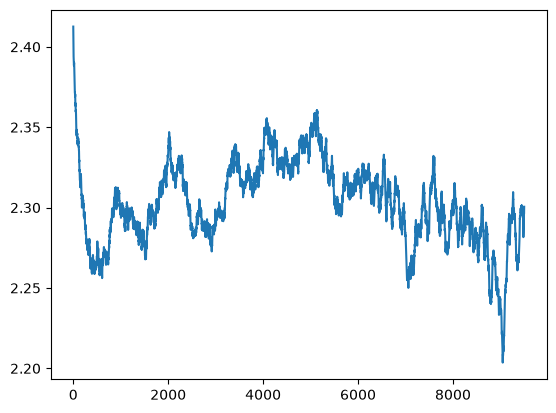

In [8]:
plt.plot(np.convolve(lossi, np.ones(500)/500, mode='valid'))

In [9]:
for _ in range(10):
	tokens = [26]
	h = torch.zeros(1, mymodel.hdim)

	while True:
		with torch.no_grad():
			logits, h = mymodel(torch.tensor([tokens[-1]]), h)

		logits = logits - logits.max(dim=1, keepdim=True).values
		cnts = logits.exp() 
		probs = cnts / cnts.sum(dim=1, keepdim=True)

		cidx = torch.multinomial(probs, num_samples=1, replacement=True).item()
		tokens.append(cidx)

		if cidx == 26:
			break

	name = ""
	for tok in tokens:
		if tok == 26:
			name += "."
		else:
			name += chr(tok + ord("a"))
	print(name)

.ovonlay.
.dasma.
.cavayn.
.eslhy.
.leeva.
.ennja.
.aveyn.
.arino.
.etori.
.jieva.
